# Notebook 03: grupo de maior risco

**Projeto de Análise de Dados e BI** · Tema: redução de faltas em consultas (no-show) em clínicas

**Equipe:** Cauê Franco, Lucio Lima e Daniel Vieira

## Objetivo deste notebook

O notebook `02_exploracao` olhou **um fator de cada vez**: a espera, o disparo de lembrete (na base, o SMS), a idade, o dia da semana e o bairro. Ele
mostrou que a espera é o fator mais associado à falta e que adolescentes e jovens faltam mais, mas deixou uma dúvida:
os jovens faltam mais por serem jovens ou por marcarem com mais antecedência? Este notebook responde a pergunta que
sustenta a recomendação do projeto: **onde a falta se concentra quando cruzamos espera e idade?**

- **De onde vêm os dados:** só do arquivo `dados/tratados/consultas_tratadas.csv`, gerado pelo notebook
  `01_limpeza`. Este notebook **nunca lê o arquivo original** e **não altera** a base tratada (o hash dela é conferido
  logo na carga).
- **Os mesmos números do dashboard:** o cruzamento de idade e espera, o grupo de maior risco e as faltas dele acima
  da média daqui são os mesmos que o dashboard mostra na aba "Grupo de risco e disparo".

## Definições (as mesmas do projeto inteiro)

- **Taxa de falta** = consultas com `faltou = 1` ÷ total de consultas, em %.
- **Espera** (`dias_espera`) = dias de calendário entre o agendamento e a consulta.
- **Faixas de idade e de espera:** as da base tratada, com os mesmos rótulos (`0-12`, `13-17`, `18-29`, `30-44`,
  `45-59`, `60+` e `Mesmo dia`, `1-7 dias`, `8-15 dias`, `16-30 dias`, `31+ dias`).
- **Grupo de maior risco** = idade de **13 a 29 anos** (faixas `13-17` e `18-29`) **e** espera de **16 dias ou mais**
  (faixas `16-30 dias` e `31+ dias`).
- **Espera longa** = espera de **16 dias ou mais**, em todas as idades (só como comparação, na seção 2).
- **Faltas acima da média** = faltas do grupo de maior risco **menos** as faltas que ele teria se faltasse na taxa
  geral da base (consultas do grupo x taxa geral).

## As 4 seções

1. A falta muda quando cruzamos espera e idade?
2. Qual é o grupo de maior risco e de que tamanho ele é?
3. Quanto o grupo de risco falta acima da média?
4. Leitura e limites

Em cada seção: a **pergunta**, o código, o gráfico e uma **leitura** com os números que o próprio notebook calculou.

## Preparação: bibliotecas, cores e carga da base tratada

In [1]:
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

CAMINHO_TRATADO = "../dados/tratados/consultas_tratadas.csv"
# SHA-256 da base tratada gerada pelo notebook 01 (conferido em 2026-11-23): garante que lemos a mesma base de sempre
HASH_TRATADA = "3b309578c06e1e5fa5f424606ec7edeb618c89f2d3a09f3dcd195d49bb7c20b9"

# Cores e estilo dos gráficos: as mesmas do notebook 02
SUPERFICIE = "#fcfcfb"
TEXTO = "#0b0b0b"
TEXTO_2 = "#52514e"
GRADE = "#e1e0d9"
EIXO = "#c3c2b7"
AZUL = "#2a78d6"      # cor principal
LARANJA = "#eb6834"   # segunda cor, só quando há dois grupos
VERMELHO = "#e34948"
NEUTRO = "#f0efec"
AZUL_CLARO = "#86b6ef"  # o mesmo azul, mais claro: para o que não é o destaque do gráfico

# Escala do mapa de calor: um tom só (azul), do claro (pouca falta) para o escuro (muita falta)
RAMPA_AZUL = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#104281"]

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": EIXO, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "text.color": TEXTO, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlepad": 12,
    "axes.labelsize": 10, "font.size": 10, "figure.dpi": 100, "legend.frameon": False,
})

# Ordem das categorias (o CSV não guarda ordem): os rótulos são exatamente os do contrato da base tratada
ORDEM_DIA_SEMANA = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta", "Sábado"]
ORDEM_FAIXA_ETARIA = ["0-12", "13-17", "18-29", "30-44", "45-59", "60+"]
ORDEM_FAIXA_ESPERA = ["Mesmo dia", "1-7 dias", "8-15 dias", "16-30 dias", "31+ dias"]

# O grupo de maior risco, definido pelas faixas da base tratada
FAIXAS_ETARIAS_RISCO = ["13-17", "18-29"]
FAIXAS_ESPERA_RISCO = ["16-30 dias", "31+ dias"]

COLUNAS_ESPERADAS = [
    "paciente_id", "consulta_id", "sexo", "data_agendamento", "data_consulta", "idade", "bairro",
    "bolsa_familia", "hipertensao", "diabetes", "alcoolismo", "recebeu_sms", "deficiencia", "faltou",
    "dias_espera", "dia_semana", "faixa_etaria", "faixa_espera", "tem_deficiencia",
]

In [2]:
# Antes de ler: o arquivo é exatamente a base tratada gerada pelo notebook 01?
sha256 = hashlib.sha256()
with open(CAMINHO_TRATADO, "rb") as arquivo:
    for bloco in iter(lambda: arquivo.read(1 << 20), b""):
        sha256.update(bloco)
assert sha256.hexdigest() == HASH_TRATADA, "a base tratada mudou: o hash não bate com o do notebook 01"

# paciente_id é só um identificador: lido como texto
df = pd.read_csv(
    CAMINHO_TRATADO,
    dtype={"paciente_id": str},
    parse_dates=["data_agendamento", "data_consulta"],
)

# O CSV não guarda a ordem das categorias; aqui ela é redefinida com os rótulos exatos do contrato
df["dia_semana"] = pd.Categorical(df["dia_semana"], categories=ORDEM_DIA_SEMANA, ordered=True)
df["faixa_etaria"] = pd.Categorical(df["faixa_etaria"], categories=ORDEM_FAIXA_ETARIA, ordered=True)
df["faixa_espera"] = pd.Categorical(df["faixa_espera"], categories=ORDEM_FAIXA_ESPERA, ordered=True)

# Conferência da carga: se algum rótulo não bater com o contrato, a categoria vira nula e o assert para o notebook
assert len(df) == 110_521, f"linhas inesperadas: {len(df)}"
assert df.shape[1] == 19
assert list(df.columns) == COLUNAS_ESPERADAS, "as colunas não batem com o contrato da base tratada"
assert df["faltou"].sum() == 22_314, f"faltas inesperadas: {df['faltou'].sum()}"
for coluna in ["dia_semana", "faixa_etaria", "faixa_espera"]:
    assert df[coluna].notna().all(), f"rótulo fora do contrato em {coluna}"
assert set(FAIXAS_ETARIAS_RISCO) <= set(ORDEM_FAIXA_ETARIA) and set(FAIXAS_ESPERA_RISCO) <= set(ORDEM_FAIXA_ESPERA)

print("OK: o hash da base tratada bate com o do notebook 01.")
print(f"Base tratada carregada: {len(df):_} linhas, {df.shape[1]} colunas e {df['faltou'].sum():_} faltas.".replace("_", "."))
df.head()

OK: o hash da base tratada bate com o do notebook 01.
Base tratada carregada: 110.521 linhas, 19 colunas e 22.314 faltas.


,paciente_id,consulta_id,sexo,data_agendamento,data_consulta,idade,bairro,bolsa_familia,hipertensao,diabetes,alcoolismo,recebeu_sms,deficiencia,faltou,dias_espera,dia_semana,faixa_etaria,faixa_espera,tem_deficiencia
0,29872499824296,5642903,F,2016-04-29,2016-04-29,62,JARDIM DA PENHA,0,1,0,0,0,0,0,0,Sexta,60+,Mesmo dia,0
1,558997776694438,5642503,M,2016-04-29,2016-04-29,56,JARDIM DA PENHA,0,0,0,0,0,0,0,0,Sexta,45-59,Mesmo dia,0
2,4262962299951,5642549,F,2016-04-29,2016-04-29,62,MATA DA PRAIA,0,0,0,0,0,0,0,0,Sexta,60+,Mesmo dia,0
3,867951213174,5642828,F,2016-04-29,2016-04-29,8,PONTAL DE CAMBURI,0,0,0,0,0,0,0,0,Sexta,0-12,Mesmo dia,0
4,8841186448183,5642494,F,2016-04-29,2016-04-29,56,JARDIM DA PENHA,0,1,1,0,0,0,0,0,Sexta,45-59,Mesmo dia,0


## Funções de apoio

As mesmas do notebook 02, para as taxas serem calculadas **sempre do mesmo jeito**, mais duas novas:

- `taxa_por(df, coluna)`: tabela com `consultas`, `faltas` e `taxa_pct` (a taxa de falta em %) para cada categoria
  da coluna, na ordem da categoria;
- `grafico_taxa(...)`: gráfico de barras da taxa, com a linha tracejada da taxa geral e o valor em cada barra;
- `fmt_num`, `fmt_pct`: formatação em português (vírgula decimal e ponto de milhar);
- **novas:** `resumo_recorte(mascara)`, que mede um recorte da base (consultas, faltas, taxa e quanto ele representa
  das consultas e das faltas), e `cor_do_texto(cor)`, que escolhe preto ou branco para o número escrito em cima de uma
  célula do mapa de calor (o que tiver mais contraste).

In [3]:
TAXA_GERAL = df["faltou"].mean() * 100  # taxa de falta geral, em %
TOTAL_CONSULTAS = len(df)
TOTAL_FALTAS = int(df["faltou"].sum())


def fmt_num(x):
    # 110521 -> "110.521"
    return f"{x:,.0f}".replace(",", ".")


def fmt_pct(x, casas=1):
    # 20.19 -> "20,2%"
    return f"{x:.{casas}f}".replace(".", ",") + "%"


def taxa_por(df, coluna):
    # Uma linha por categoria de `coluna`: consultas, faltas e taxa de falta (faltas / consultas, em %)
    g = df.groupby(coluna, observed=False)["faltou"].agg(consultas="size", faltas="sum")
    g["taxa_pct"] = g["faltas"] / g["consultas"] * 100
    return g.reset_index()


def resumo_recorte(mascara):
    # Mede um recorte da base: consultas, faltas, taxa (%) e a parte dele nas consultas e nas faltas (%)
    # Os nomes dos campos são os mesmos do arquivo de dados do dashboard (painel.json)
    consultas = int(mascara.sum())
    faltas = int(df.loc[mascara, "faltou"].sum())
    return {
        "consultas": consultas,
        "faltas": faltas,
        "taxa": faltas / consultas * 100,
        "pct_consultas": consultas / TOTAL_CONSULTAS * 100,
        "pct_faltas": faltas / TOTAL_FALTAS * 100,
    }


def cor_do_texto(cor_fundo):
    # Preto ou branco: o que tiver mais contraste com o fundo (luminância relativa, como na regra WCAG)
    canais = [c / 12.92 if c <= 0.04045 else ((c + 0.055) / 1.055) ** 2.4 for c in to_rgb(cor_fundo)]
    luminancia = 0.2126 * canais[0] + 0.7152 * canais[1] + 0.0722 * canais[2]
    contraste_preto = (luminancia + 0.05) / 0.05
    contraste_branco = 1.05 / (luminancia + 0.05)
    return TEXTO if contraste_preto >= contraste_branco else "#ffffff"


def grafico_taxa(tabela, coluna, titulo, ax=None, mostrar_n=False, xlabel=None, cor=AZUL):
    # Colunas da taxa de falta (%) por categoria, com a linha tracejada da taxa geral e o valor em cada coluna
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 4.5))
    rotulos = tabela[coluna].astype(str).tolist()
    if mostrar_n:
        rotulos = [f"{r}\n(n = {fmt_num(n)})" for r, n in zip(rotulos, tabela["consultas"])]
    valores = tabela["taxa_pct"].to_numpy()
    teto = max(valores.max(), TAXA_GERAL) * 1.25
    posicoes = np.arange(len(valores))
    ax.bar(posicoes, valores, width=0.55 if len(valores) > 2 else 0.3, color=cor)
    ax.set_xticks(posicoes, rotulos)
    ax.axhline(TAXA_GERAL, color=TEXTO_2, linestyle="--", linewidth=1.2)
    ax.set_ylim(0, teto)
    for p, v in zip(posicoes, valores):
        ax.text(p, v + teto * 0.012, fmt_pct(v), ha="center", va="bottom", color=TEXTO,
                bbox={"facecolor": SUPERFICIE, "edgecolor": "none", "pad": 1.5})
    ax.set_ylabel("Taxa de falta (%)")
    ax.yaxis.grid(True, color=GRADE, linewidth=0.8)
    if xlabel:
        ax.set_xlabel(xlabel)
    ax.set_axisbelow(True)
    linha_geral = Line2D([0], [0], color=TEXTO_2, linestyle="--", linewidth=1.2,
                         label=f"Taxa geral: {fmt_pct(TAXA_GERAL)}")
    ax.legend(handles=[linha_geral], loc="upper left")
    ax.set_title(titulo, loc="left")
    return ax


# Testes das funções de apoio
por_espera = taxa_por(df, "faixa_espera")
assert por_espera["consultas"].sum() == TOTAL_CONSULTAS and por_espera["faltas"].sum() == TOTAL_FALTAS
base_inteira = resumo_recorte(pd.Series(True, index=df.index))
assert base_inteira["consultas"] == TOTAL_CONSULTAS and base_inteira["faltas"] == TOTAL_FALTAS
assert base_inteira["pct_consultas"] == 100 and base_inteira["pct_faltas"] == 100
assert round(base_inteira["taxa"], 1) == round(TAXA_GERAL, 1) == 20.2
assert cor_do_texto("#ffffff") == TEXTO and cor_do_texto("#000000") == "#ffffff"
print(f"OK: as funções fecham com o total de consultas e de faltas, e a taxa geral é {fmt_pct(TAXA_GERAL)}.")

OK: as funções fecham com o total de consultas e de faltas, e a taxa geral é 20,2%.


## Seção 1: A falta muda quando cruzamos espera e idade?

**Pergunta:** o notebook 02 mostrou que a falta sobe com a espera e que jovens faltam mais. Mas esses dois fatores
podem estar misturados: se os jovens marcassem com mais antecedência, a "falta dos jovens" seria, na verdade, a falta
de quem espera mais. Para separar, cruzamos as **6 faixas de idade** com as **5 faixas de espera** (30 células) e
calculamos a taxa de falta de cada célula, junto com o número de consultas dela (taxa com poucas consultas é pouco
confiável).

In [4]:
cruzamento = (
    df.groupby(["faixa_etaria", "faixa_espera"], observed=False)["faltou"]
    .agg(consultas="size", faltas="sum")
    .reset_index()
)
cruzamento["taxa"] = cruzamento["faltas"] / cruzamento["consultas"] * 100

# Tabelas largas: idade nas linhas, espera nas colunas
tabela_taxa = cruzamento.pivot(index="faixa_etaria", columns="faixa_espera", values="taxa")
tabela_n = cruzamento.pivot(index="faixa_etaria", columns="faixa_espera", values="consultas")
tabela_taxa = tabela_taxa.reindex(index=ORDEM_FAIXA_ETARIA, columns=ORDEM_FAIXA_ESPERA)
tabela_n = tabela_n.reindex(index=ORDEM_FAIXA_ETARIA, columns=ORDEM_FAIXA_ESPERA)

# Testes: 30 células, nenhuma vazia, e as somas fecham com a base inteira
assert len(cruzamento) == 30, f"células inesperadas: {len(cruzamento)}"
assert (cruzamento["consultas"] > 0).all(), "há célula sem consultas"
assert cruzamento["consultas"].sum() == TOTAL_CONSULTAS and cruzamento["faltas"].sum() == TOTAL_FALTAS
assert tabela_taxa.notna().all().all()
print("OK: 30 células, todas com consultas; somam 110.521 consultas e 22.314 faltas.")

print("\nTaxa de falta (%) por idade (linhas) e espera (colunas)")
display(tabela_taxa.round(1))
print("Número de consultas de cada célula")
display(tabela_n)

OK: 30 células, todas com consultas; somam 110.521 consultas e 22.314 faltas.

Taxa de falta (%) por idade (linhas) e espera (colunas)


faixa_espera,Mesmo dia,1-7 dias,8-15 dias,16-30 dias,31+ dias
faixa_etaria,,,,,
0-12,5.6,25.0,32.9,33.5,38.2
13-17,11.7,32.6,36.3,40.1,42.5
18-29,5.1,30.8,36.8,39.7,40.1
30-44,3.5,26.9,32.2,36.1,37.3
45-59,3.3,21.5,26.8,28.6,28.1
60+,3.1,18.5,22.7,22.5,22.8


Número de consultas de cada célula


faixa_espera,Mesmo dia,1-7 dias,8-15 dias,16-30 dias,31+ dias
faixa_etaria,,,,,
0-12,8682,4662,2626,3047,2018
13-17,2530,1539,834,908,532
18-29,5953,4465,2329,2614,1368
30-44,7610,6217,2935,3287,1972
45-59,7466,7635,2612,3203,2305
60+,6321,7667,2192,2809,2183


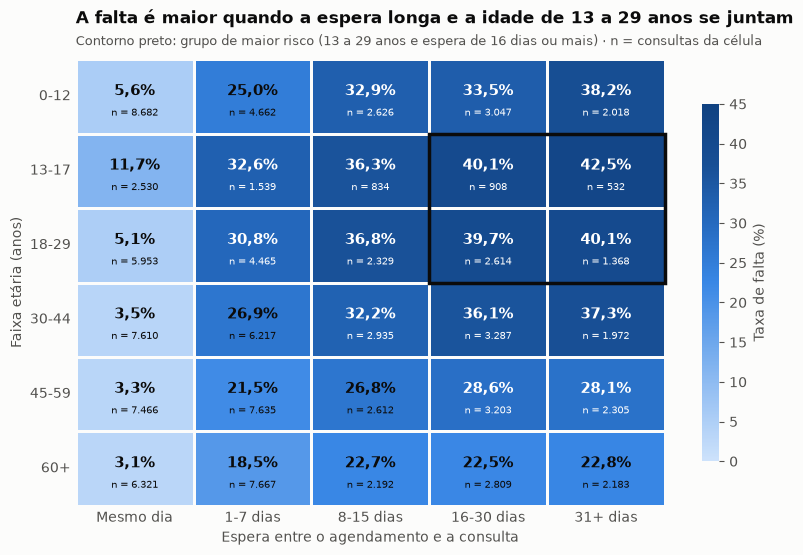

In [5]:
cores_seq = LinearSegmentedColormap.from_list("azul_sequencial", RAMPA_AZUL)
TETO_ESCALA = 45  # a escala vai de 0% a 45%, um pouco acima da maior célula

fig, ax = plt.subplots(figsize=(9.5, 5.8))
sns.heatmap(tabela_taxa, cmap=cores_seq, vmin=0, vmax=TETO_ESCALA, annot=False, linewidths=2,
            linecolor=SUPERFICIE, cbar_kws={"label": "Taxa de falta (%)", "shrink": 0.8}, ax=ax)

# Em cada célula: a taxa (em destaque) e o número de consultas, na cor de texto com mais contraste
for i, idade in enumerate(ORDEM_FAIXA_ETARIA):
    for j, espera in enumerate(ORDEM_FAIXA_ESPERA):
        taxa = tabela_taxa.loc[idade, espera]
        cor = cor_do_texto(cores_seq(taxa / TETO_ESCALA))
        ax.text(j + 0.5, i + 0.43, fmt_pct(taxa), ha="center", va="center", color=cor, fontsize=10.5,
                fontweight="bold")
        ax.text(j + 0.5, i + 0.72, f"n = {fmt_num(tabela_n.loc[idade, espera])}", ha="center", va="center",
                color=cor, fontsize=7.5)

# Contorno nas 4 células do grupo de maior risco (13 a 29 anos e espera de 16 dias ou mais)
linha_0 = ORDEM_FAIXA_ETARIA.index(FAIXAS_ETARIAS_RISCO[0])
coluna_0 = ORDEM_FAIXA_ESPERA.index(FAIXAS_ESPERA_RISCO[0])
ax.add_patch(Rectangle((coluna_0, linha_0), len(FAIXAS_ESPERA_RISCO), len(FAIXAS_ETARIAS_RISCO), fill=False,
                       edgecolor=TEXTO, linewidth=2.5, clip_on=False))

ax.set_xlabel("Espera entre o agendamento e a consulta")
ax.set_ylabel("Faixa etária (anos)")
ax.set_yticklabels(ORDEM_FAIXA_ETARIA, rotation=0)
ax.tick_params(length=0)
ax.set_title("A falta é maior quando a espera longa e a idade de 13 a 29 anos se juntam", loc="left", pad=26)
ax.text(0, 1.025, "Contorno preto: grupo de maior risco (13 a 29 anos e espera de 16 dias ou mais) · "
        "n = consultas da célula", transform=ax.transAxes, ha="left", va="bottom", color=TEXTO_2, fontsize=9)
plt.show()

In [6]:
# Os números que a leitura abaixo cita, calculados aqui (e conferidos pelos asserts)
maior = cruzamento.loc[cruzamento["taxa"].idxmax()]
menor = cruzamento.loc[cruzamento["taxa"].idxmin()]
print(f"Célula mais alta: {maior['faixa_etaria']} anos e espera {maior['faixa_espera']}: {fmt_pct(maior['taxa'])} "
      f"({fmt_num(maior['consultas'])} consultas)")
print(f"Célula mais baixa: {menor['faixa_etaria']} anos e espera {menor['faixa_espera']}: {fmt_pct(menor['taxa'])} "
      f"({fmt_num(menor['consultas'])} consultas)")

print("\nMesmo dia, por idade:", " | ".join(f"{i} {fmt_pct(tabela_taxa.loc[i, 'Mesmo dia'])}" for i in ORDEM_FAIXA_ETARIA))
print("16-30 dias, por idade:", " | ".join(f"{i} {fmt_pct(tabela_taxa.loc[i, '16-30 dias'])}" for i in ORDEM_FAIXA_ETARIA))
print("60+, por espera:", " | ".join(f"{e} {fmt_pct(tabela_taxa.loc['60+', e])}" for e in ORDEM_FAIXA_ESPERA))

celulas_risco = cruzamento[cruzamento["faixa_etaria"].isin(FAIXAS_ETARIAS_RISCO)
                           & cruzamento["faixa_espera"].isin(FAIXAS_ESPERA_RISCO)]
quatro_maiores = cruzamento.nlargest(4, "taxa")
print(f"\nAs 4 células do grupo de maior risco vão de {fmt_pct(celulas_risco['taxa'].min())} "
      f"a {fmt_pct(celulas_risco['taxa'].max())}.")
print(f"Quinta maior célula: {cruzamento.nlargest(5, 'taxa').iloc[-1]['faixa_etaria']} anos com "
      f"{cruzamento.nlargest(5, 'taxa').iloc[-1]['faixa_espera']}: {fmt_pct(cruzamento.nlargest(5, 'taxa').iloc[-1]['taxa'])}")
poucas = cruzamento[cruzamento["consultas"] < 100]
print(f"Células com menos de 100 consultas: {len(poucas)} (a menor tem {fmt_num(cruzamento['consultas'].min())}).")

# A taxa sobe com a espera em todas as idades: do mesmo dia para 1-7 dias, e de 1-7 dias para 16 dias ou mais
for idade in ORDEM_FAIXA_ETARIA:
    linha = tabela_taxa.loc[idade]
    assert linha["Mesmo dia"] < linha["1-7 dias"] < min(linha["16-30 dias"], linha["31+ dias"]), idade

# Se algum destes asserts falhar, a leitura precisa mudar
assert (maior["faixa_etaria"], maior["faixa_espera"], round(maior["taxa"], 1)) == ("13-17", "31+ dias", 42.5)
assert (menor["faixa_etaria"], menor["faixa_espera"], round(menor["taxa"], 1)) == ("60+", "Mesmo dia", 3.1)
assert set(zip(quatro_maiores["faixa_etaria"], quatro_maiores["faixa_espera"])) == set(
    zip(celulas_risco["faixa_etaria"], celulas_risco["faixa_espera"])), "as 4 maiores células não são as do grupo"
assert round(tabela_taxa.loc["18-29", "Mesmo dia"], 1) == 5.1 and round(tabela_taxa.loc["13-17", "Mesmo dia"], 1) == 11.7
assert round(tabela_taxa.loc["13-17", "16-30 dias"], 1) == 40.1 and round(tabela_taxa.loc["60+", "16-30 dias"], 1) == 22.5
assert len(poucas) == 0
print("\nOK: em todas as idades a taxa sobe com a espera, e as 4 maiores células são as do grupo de maior risco.")

Célula mais alta: 13-17 anos e espera 31+ dias: 42,5% (532 consultas)
Célula mais baixa: 60+ anos e espera Mesmo dia: 3,1% (6.321 consultas)

Mesmo dia, por idade: 0-12 5,6% | 13-17 11,7% | 18-29 5,1% | 30-44 3,5% | 45-59 3,3% | 60+ 3,1%
16-30 dias, por idade: 0-12 33,5% | 13-17 40,1% | 18-29 39,7% | 30-44 36,1% | 45-59 28,6% | 60+ 22,5%
60+, por espera: Mesmo dia 3,1% | 1-7 dias 18,5% | 8-15 dias 22,7% | 16-30 dias 22,5% | 31+ dias 22,8%

As 4 células do grupo de maior risco vão de 39,7% a 42,5%.
Quinta maior célula: 0-12 anos com 31+ dias: 38,2%
Células com menos de 100 consultas: 0 (a menor tem 532).

OK: em todas as idades a taxa sobe com a espera, e as 4 maiores células são as do grupo de maior risco.


**Leitura.** Em **todas as faixas de idade**, a falta sobe com a espera: no mesmo dia ela fica entre 3,1% e 11,7%, e
com 16 dias ou mais passa de 20% em todas as idades. A célula mais alta é a de **13 a 17 anos com 31 dias ou mais
(42,5%**, 532 consultas); a mais baixa, a de **60 anos ou mais no mesmo dia (3,1%**, 6.321 consultas).

A idade também continua pesando **dentro** de cada faixa de espera: com 16 a 30 dias de espera, quem tem 13 a 17 anos
falta em 40,1% das consultas, e quem tem 60 ou mais, em 22,5%. Um fator não apaga o outro, e as taxas mais altas
aparecem quando os dois se juntam: as **quatro maiores células do mapa** são exatamente as do contorno, **13 a 29 anos
com 16 dias ou mais de espera** (de 39,7% a 42,5%; a quinta maior, 0 a 12 anos com 31 dias ou mais, fica em 38,2%).

Isso responde em parte à dúvida do notebook 02. No mesmo dia, quem tem 18 a 29 anos falta só 5,1%, perto das outras
idades (só os de 13 a 17 se destacam, com 11,7%); a diferença dos jovens aparece com força quando há espera. Já quem
tem 60 anos ou mais é o grupo mais estável: a taxa sobe até 8 a 15 dias (22,7%) e depois fica parada (22,5% e 22,8%).

Nenhuma célula tem menos de 100 consultas (a menor tem 532), então todas as taxas do mapa têm amostra suficiente. Como
no notebook 02, a leitura é **descritiva**: mostra onde a falta se concentra, não por que ela acontece.

## Seção 2: Qual é o grupo de maior risco e de que tamanho ele é?

**Pergunta:** a seção 1 mostrou que a falta é maior quando a espera longa e a idade de 13 a 29 anos se juntam. Esse é
o **grupo de maior risco**, o alvo do agente de disparo de lembretes. Quantas consultas ele tem, quanto ele
falta e quanto das faltas ele concentra? Comparamos com a **espera longa** (16 dias ou mais, em todas as idades) e
com a base inteira.

In [7]:
# O grupo pelas faixas da base tratada (é assim que o dashboard também calcula)
no_grupo = df["faixa_etaria"].isin(FAIXAS_ETARIAS_RISCO) & df["faixa_espera"].isin(FAIXAS_ESPERA_RISCO)
na_espera_longa = df["faixa_espera"].isin(FAIXAS_ESPERA_RISCO)

grupo_risco = resumo_recorte(no_grupo)
espera_longa = resumo_recorte(na_espera_longa)

# Teste 1: pelas faixas ou pelas colunas cruas (idade e dias_espera), o recorte é o mesmo
no_grupo_cru = df["idade"].between(13, 29) & (df["dias_espera"] >= 16)
assert no_grupo.equals(no_grupo_cru), "o grupo pelas faixas difere do grupo pelas colunas cruas"
assert na_espera_longa.equals(df["dias_espera"] >= 16), "a espera longa pelas faixas difere da coluna crua"

# Teste 2: o grupo é a soma das 4 células correspondentes do cruzamento da seção 1
assert grupo_risco["consultas"] == celulas_risco["consultas"].sum()
assert grupo_risco["faltas"] == celulas_risco["faltas"].sum()
print("OK: o grupo e a espera longa são iguais pelas faixas e pelas colunas cruas, e o grupo fecha com o cruzamento.")

resumo = pd.DataFrame(
    [grupo_risco, espera_longa, base_inteira],
    index=["Grupo de maior risco (13 a 29 anos e 16+ dias)", "Espera longa (16+ dias, todas as idades)", "Base inteira"],
)
resumo_formatado = pd.DataFrame({
    "consultas": resumo["consultas"].map(fmt_num),
    "faltas": resumo["faltas"].map(fmt_num),
    "taxa de falta": resumo["taxa"].map(fmt_pct),
    "% das consultas": resumo["pct_consultas"].map(fmt_pct),
    "% das faltas": resumo["pct_faltas"].map(fmt_pct),
})
display(resumo_formatado)
print(f"Taxa do grupo ÷ taxa geral: {grupo_risco['taxa'] / TAXA_GERAL:.1f} vezes".replace(".", ","))
print(f"Taxa da espera longa ÷ taxa geral: {espera_longa['taxa'] / TAXA_GERAL:.1f} vezes".replace(".", ","))

OK: o grupo e a espera longa são iguais pelas faixas e pelas colunas cruas, e o grupo fecha com o cruzamento.


,consultas,faltas,taxa de falta,% das consultas,% das faltas
Grupo de maior risco (13 a 29 anos e 16+ dias),5.422,2.178,"40,2%","4,9%","9,8%"
"Espera longa (16+ dias, todas as idades)",26.246,8.584,"32,7%","23,7%","38,5%"
Base inteira,110.521,22.314,"20,2%","100,0%","100,0%"


Taxa do grupo ÷ taxa geral: 2,0 vezes
Taxa da espera longa ÷ taxa geral: 1,6 vezes


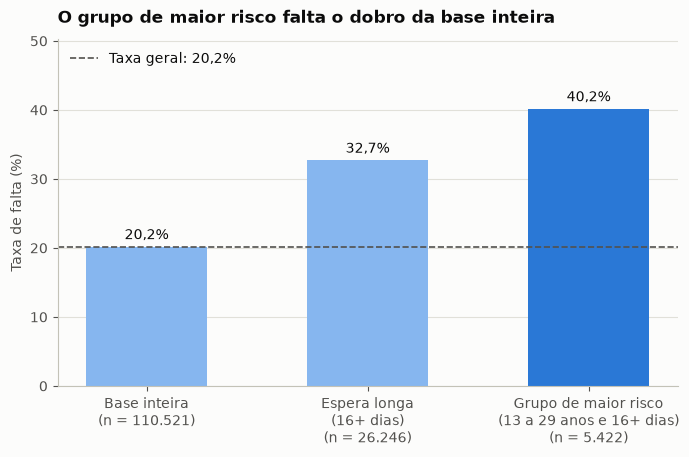

In [8]:
comparacao = pd.DataFrame({
    "recorte": ["Base inteira", "Espera longa\n(16+ dias)", "Grupo de maior risco\n(13 a 29 anos e 16+ dias)"],
    "consultas": [base_inteira["consultas"], espera_longa["consultas"], grupo_risco["consultas"]],
    "taxa_pct": [base_inteira["taxa"], espera_longa["taxa"], grupo_risco["taxa"]],
})
grafico_taxa(comparacao, "recorte", "O grupo de maior risco falta o dobro da base inteira", mostrar_n=True,
             cor=[AZUL_CLARO, AZUL_CLARO, AZUL])
plt.show()

In [9]:
# Os números que a leitura abaixo cita (se algum assert falhar, a leitura precisa mudar)
assert (grupo_risco["consultas"], grupo_risco["faltas"]) == (5_422, 2_178)
assert round(grupo_risco["taxa"], 1) == 40.2
assert round(grupo_risco["pct_consultas"], 1) == 4.9 and round(grupo_risco["pct_faltas"], 1) == 9.8
assert round(grupo_risco["taxa"] / TAXA_GERAL, 1) == 2.0
assert (espera_longa["consultas"], espera_longa["faltas"]) == (26_246, 8_584)
assert round(espera_longa["taxa"], 1) == 32.7
assert round(espera_longa["pct_consultas"], 1) == 23.7 and round(espera_longa["pct_faltas"], 1) == 38.5
print("OK: os números citados na leitura batem com o que foi calculado.")

OK: os números citados na leitura batem com o que foi calculado.


**Leitura.** O grupo de maior risco (13 a 29 anos **e** espera de 16 dias ou mais) tem **5.422 consultas**, só
**4,9%** do total, e falta em **40,2%** delas: **o dobro** da taxa geral (20,2%). Ele concentra **9,8% das faltas**
(2.178 de 22.314). Por ser pequeno (cerca de 1 em cada 20 consultas da agenda), o **reforço de lembretes** (por exemplo,
um segundo contato perto da data) pode ser dirigido só a ele, com custo baixo, em vez de ser aplicado a todos os
pacientes.

A **espera longa**, sozinha (16 dias ou mais, em todas as idades), é bem maior: **26.246 consultas** (23,7% do
total), com **32,7%** de falta, e concentra **38,5% das faltas** (8.584), quase 4 em cada 10. Ela serve de
comparação: o grupo de maior risco é bem menor e falta ainda mais.

**Conferência:** estes números são iguais aos preliminares calculados antes do notebook (5.422 consultas e 40,2% para o
grupo; 26.246 consultas, 32,7% e 38,5% das faltas para a espera longa). A partir daqui, eles são os números oficiais do
projeto.

## Seção 3: Quanto o grupo de risco falta acima da média?

**Pergunta:** se o grupo de maior risco faltasse como a média da base, quantas faltas haveria nele? A diferença para as
faltas que ele realmente tem é o tamanho do problema que o agente de disparo de lembretes quer atacar. A conta é:
**faltas do grupo menos as faltas que ele teria na taxa geral** (consultas do grupo x taxa geral da base).

Depois, para apoiar o primeiro passo do agente (o **Classifica**, que calcula o risco pela espera e pela idade), mostramos
quantas faltas são esperadas **a cada 100 consultas** em cada faixa de espera. A espera é o critério principal do risco.

Faltas do grupo: 2.178
Faltas que o grupo teria na taxa geral (20,2% de 5.422 consultas): 1.095
Faltas acima da média: 1.083
OK: o grupo tem cerca de 1.083 faltas acima da média da base.



,consultas,taxa de falta,faltas a cada 100 consultas
faixa de espera,,,
Mesmo dia,38.562,"4,6%","4,6"
1-7 dias,32.185,"24,1%","24,1"
8-15 dias,13.528,"30,8%","30,8"
16-30 dias,15.868,"32,5%","32,5"
31+ dias,10.378,"33,0%","33,0"


OK: as taxas por faixa de espera batem com as do notebook 02.


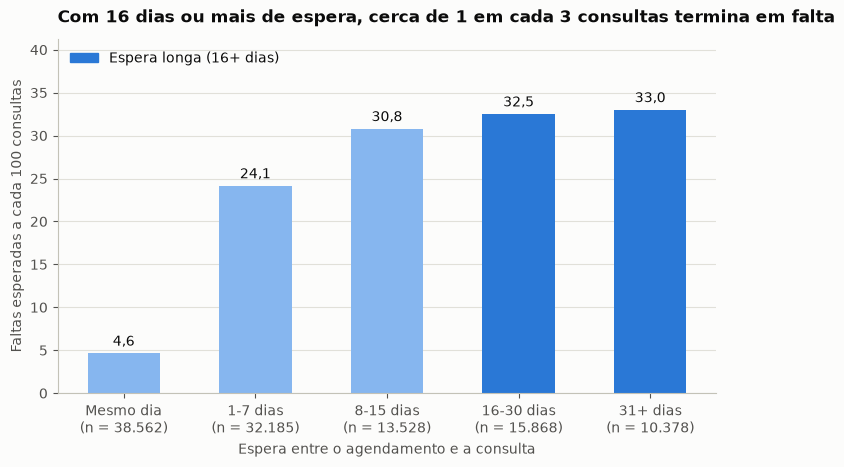

In [10]:
# O número novo: faltas do grupo acima da média = faltas do grupo - consultas do grupo x taxa geral
faltas_esperadas_no_grupo = grupo_risco["consultas"] * TAXA_GERAL / 100  # as faltas que o grupo teria na taxa geral
faltas_acima_da_media = grupo_risco["faltas"] - faltas_esperadas_no_grupo

print(f"Faltas do grupo: {fmt_num(grupo_risco['faltas'])}")
print(f"Faltas que o grupo teria na taxa geral ({fmt_pct(TAXA_GERAL)} de {fmt_num(grupo_risco['consultas'])} consultas): "
      f"{fmt_num(faltas_esperadas_no_grupo)}")
print(f"Faltas acima da média: {fmt_num(faltas_acima_da_media)}")

# Teste: a conta fecha com os números oficiais (o mesmo valor que o painel.json do dashboard traz)
assert (grupo_risco["consultas"], grupo_risco["faltas"]) == (5_422, 2_178)
assert round(faltas_esperadas_no_grupo) == 1_095
assert round(faltas_acima_da_media) == 1_083, f"faltas acima da média inesperadas: {faltas_acima_da_media}"
print("OK: o grupo tem cerca de 1.083 faltas acima da média da base.\n")

faltas_por_100 = taxa_por(df, "faixa_espera").rename(columns={"taxa_pct": "taxa"})
# A cada 100 consultas, quantas terminam em falta (supondo que as próximas se comportem como as da base)
faltas_por_100["faltas_a_cada_100"] = faltas_por_100["taxa"]

display(pd.DataFrame({
    "faixa de espera": faltas_por_100["faixa_espera"].astype(str),
    "consultas": faltas_por_100["consultas"].map(fmt_num),
    "taxa de falta": faltas_por_100["taxa"].map(fmt_pct),
    "faltas a cada 100 consultas": faltas_por_100["faltas_a_cada_100"].map(lambda x: f"{x:.1f}".replace(".", ",")),
}).set_index("faixa de espera"))

# Teste: as taxas por faixa de espera são as do notebook 02
assert faltas_por_100["faixa_espera"].astype(str).tolist() == ORDEM_FAIXA_ESPERA
assert faltas_por_100["taxa"].round(1).tolist() == [4.6, 24.1, 30.8, 32.5, 33.0]
assert faltas_por_100["consultas"].sum() == TOTAL_CONSULTAS
print("OK: as taxas por faixa de espera batem com as do notebook 02.")

# Colunas: as faixas da espera longa (16 dias ou mais) em destaque
valores = faltas_por_100["faltas_a_cada_100"].to_numpy()
cores = [AZUL if f in FAIXAS_ESPERA_RISCO else AZUL_CLARO for f in ORDEM_FAIXA_ESPERA]
fig, ax = plt.subplots(figsize=(8.5, 4.6))
posicoes = np.arange(len(valores))
ax.bar(posicoes, valores, width=0.55, color=cores)
teto = valores.max() * 1.25
for p, v in zip(posicoes, valores):
    ax.text(p, v + teto * 0.012, f"{v:.1f}".replace(".", ","), ha="center", va="bottom", color=TEXTO)
rotulos = [f"{f}\n(n = {fmt_num(n)})" for f, n in zip(ORDEM_FAIXA_ESPERA, faltas_por_100["consultas"])]
ax.set_xticks(posicoes, rotulos)
ax.set_ylim(0, teto)
ax.set_ylabel("Faltas esperadas a cada 100 consultas")
ax.set_xlabel("Espera entre o agendamento e a consulta")
ax.yaxis.grid(True, color=GRADE, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(handles=[Rectangle((0, 0), 1, 1, color=AZUL, label="Espera longa (16+ dias)")],
          loc="upper left")
ax.set_title("Com 16 dias ou mais de espera, cerca de 1 em cada 3 consultas termina em falta", loc="left")
plt.show()

**Leitura.** O grupo de maior risco tem **2.178 faltas**. Se ele faltasse como a média da base (20,19%), teria cerca de
**1.095** (5.422 consultas x 20,19%). A diferença, **1.083 faltas**, é quanto ele falta **acima da média**: são
**1.083 consultas a mais em seis semanas** (o período da base), se o grupo de risco faltasse como a média.

A conta tem uma **premissa declarada**: ela supõe que as próximas consultas se comportem como as da base (as mesmas
taxas). Ela também não diz quantas dessas faltas um lembrete evitaria, só **o tamanho do problema**.

A tabela e o gráfico acima apoiam o **Classifica**: a espera é o critério principal do risco. De cada 100 consultas
marcadas com **16 a 30 dias** de espera, cerca de **32,5** terminam em falta; com **31 dias ou mais**, cerca de
**33,0**. No **mesmo dia** são só **4,6** faltas a cada 100: quase todos aparecem. As faixas intermediárias (24,1 em 1
a 7 dias e 30,8 em 8 a 15) ficam entre os dois extremos. A idade entra para refinar: com espera longa, de 13 a 29
anos a falta chega a 40,2% (seção 2).

## Seção 4: Leitura e limites

Os números que sustentam a recomendação do projeto, calculados nas seções anteriores:

In [11]:
leitura = pd.DataFrame({
    "recomendação": ["Agente de disparo de lembretes"],
    "recorte": ["13 a 29 anos e espera de 16 dias ou mais"],
    "consultas": [fmt_num(grupo_risco["consultas"])],
    "% das consultas": [fmt_pct(grupo_risco["pct_consultas"])],
    "taxa de falta": [fmt_pct(grupo_risco["taxa"])],
    "% das faltas": [fmt_pct(grupo_risco["pct_faltas"])],
    "faltas acima da média": [fmt_num(faltas_acima_da_media)],
}).set_index("recomendação")
display(leitura)
print(f"Referência: base inteira com {fmt_num(TOTAL_CONSULTAS)} consultas, {fmt_num(TOTAL_FALTAS)} faltas "
      f"e taxa de {fmt_pct(TAXA_GERAL)}.")

# Teste: a tabela traz os números que o texto abaixo cita
assert leitura.loc["Agente de disparo de lembretes", "consultas"] == "5.422"
assert leitura.loc["Agente de disparo de lembretes", "taxa de falta"] == "40,2%"
assert leitura.loc["Agente de disparo de lembretes", "% das consultas"] == "4,9%"
assert leitura.loc["Agente de disparo de lembretes", "% das faltas"] == "9,8%"
assert leitura.loc["Agente de disparo de lembretes", "faltas acima da média"] == "1.083"
print("OK: os números da tabela batem com os que o texto cita.")

,recorte,consultas,% das consultas,taxa de falta,% das faltas,faltas acima da média
recomendação,,,,,,
Agente de disparo de lembretes,13 a 29 anos e espera de 16 dias ou mais,5.422,"4,9%","40,2%","9,8%",1.083


Referência: base inteira com 110.521 consultas, 22.314 faltas e taxa de 20,2%.
OK: os números da tabela batem com os que o texto cita.


### O que os números sustentam

**Um agente de disparo de lembretes para reduzir as faltas**, com três passos:

1. **Classifica.** No agendamento, calcula o risco de falta pela espera e pela idade. De 13 a 29 anos, com 16 dias ou
   mais de espera, a falta é de **40,2%**.
2. **Dispara.** Para quem tem risco alto, manda mais de um lembrete antes da consulta e pede confirmação.
3. **Libera.** Se o paciente cancela ou não confirma, o horário é oferecido a quem está na lista de espera.

Os números que o sustentam: o grupo de maior risco é **4,9%** da agenda (5.422 consultas), falta em **40,2%** (o dobro da
taxa geral de 20,2%) e concentra **9,8%** das faltas. São **1.083 consultas a mais em seis semanas**, se o grupo de risco
faltasse como a média. É um grupo pequeno e fácil de identificar no momento do agendamento (a idade e a data já estão
no cadastro), então o contato a mais custa pouco.

### Limites

- **A análise é descritiva, não prova causa.** Os números mostram onde a falta se concentra, não por que ela acontece.
  **Na base, dentro da mesma faixa de espera, o disparo aparece junto com menos falta, o que ainda é associação.** Por isso o agente começa em teste:
  metade do grupo de risco recebe o reforço, e a outra metade não.
- **Os dados são da rede pública, usados como aproximação.** A base vem de consultas da rede pública de Vitória (ES),
  em 2016, e o projeto a usa como aproximação para uma clínica privada (premissa declarada na seção **D** do
  `docs/processo.md`). O padrão pode ser diferente em outra clínica.
- **A clínica deve conferir com os próprios dados.** Antes de aplicar o agente, o ideal é repetir este mesmo
  cruzamento (idade x espera) com a agenda da própria clínica.
- **A conta dos 1.083 é ilustrativa.** Ela supõe que as próximas consultas se comportem como as da base e não diz quantas
  faltas o lembrete evitaria, porque isso só o teste mostra.